In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy.stats import ks_2samp, anderson_ksamp

import warnings
import tqdm

## Reading samples

In [91]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

apogee = apogee[apogee.parallax > 0.]
galah = galah[(galah.parallax > 0.) ]

apogee['rel_parallax'] = apogee.parallax_error / apogee.parallax
apogee = apogee[apogee.rel_parallax < 0.1]

galah['rel_parallax'] = galah.parallax_error / galah.parallax
galah = galah[galah.rel_parallax < 0.1]


harps['rel_parallax'] = harps.parallax_error / harps.parallax
harps = harps[harps.rel_parallax < 0.1]

# Seelcting only giants
apogee = apogee[apogee.logg < 3]

# Selecting only dwarfs
galah = galah[galah.logg > 3]


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 45812 stars
galah contains 71591 stars
gr8 contains 1430 stars


In [92]:
def compare_dfs_by_source_id(df1, df2, label1='df1', label2='df2', id_col='source_id'):
    """
    Crossmatches two DataFrames by source_id and compares common numeric columns.
    
    Parameters:
        df1, df2: pandas DataFrames
        label1, label2: labels used for suffixes and reporting
        id_col: column to match on (default: 'source_id')
    
    Returns:
        merged_df: merged DataFrame with suffixes
        comparison_df: DataFrame with mean and max absolute differences per column
    """
    # Ensure ID column is string to avoid mismatches
    df1 = df1.copy()
    df2 = df2.copy()
    df1[id_col] = df1[id_col].astype(int)
    df2[id_col] = df2[id_col].astype(int)
    
    # Merge
    merged_df = pd.merge(df1, df2, on=id_col, suffixes=(f'_{label1}', f'_{label2}'))
    print(f"Matched rows: {len(merged_df)} / {len(df1)} {label1.upper()} entries")
    
    # Get common columns
    common_cols = list(set(df1.columns) & set(df2.columns))
    
    # Compare only numeric columns
    comparison_stats = []
    for col in common_cols:
        col_1 = f"{col}_{label1}"
        col_2 = f"{col}_{label2}"
        if col_1 in merged_df.columns and col_2 in merged_df.columns:
            try:
                # Convert to numeric
                series_1 = pd.to_numeric(merged_df[col_1], errors='coerce')
                series_2 = pd.to_numeric(merged_df[col_2], errors='coerce')
                diff = (series_1 - series_2).abs()
                comparison_stats.append({
                    'column': col,
                    'mean_abs_diff': diff.mean(),
                    'max_abs_diff': diff.max(),
                    'n_nan': diff.isna().sum()
                })
            except Exception:
                continue

    comparison_df = pd.DataFrame(comparison_stats)
    comparison_df.sort_values(by='mean_abs_diff', ascending=False, inplace=True)
    
    return merged_df, comparison_df


In [93]:
merged_harps_apogee, comp_harps_apogee = compare_dfs_by_source_id(harps, apogee, label1='harps', label2='apogee')
merged_harps_galah, comp_harps_galah  = compare_dfs_by_source_id(harps, galah, label1='harps', label2='galah')
merged_galah_apogee, comp_galah_apogee = compare_dfs_by_source_id(galah, apogee, label1='galah', label2='apogee')
#merged_galah_gr8, comp_galah_gr8 = compare_dfs_by_source_id(galah, gr8, label1='galah', label2='gr8')
#merged_apogee_gr8, comp_apogee_gr8 = compare_dfs_by_source_id(apogee, gr8, label1='galah', label2='gr8')

Matched rows: 0 / 798 HARPS entries
Matched rows: 6 / 798 HARPS entries
Matched rows: 0 / 71591 GALAH entries


In [103]:
merged_harps_galah

,Unnamed: 0,source_id,Star,ra_harps,dec_harps,parallax_harps,parallax_error_harps,pmra_harps,pmra_error_harps,pmdec_harps,...,Tr_galah,TrTp_galah,Tz_galah,U_galah,V_galah,W_galah,jp_galah,jr_galah,jz_galah,rel_parallax_galah
0,163,5794923536819249408,HD139536,235.994561,-71.705230,16.086907,0.010863,-122.660772,0.009262,-80.941579,...,0.163899,2.333511,0.087175,-42.053888,-19.152510,8.013639,1723.435060,13.063603,1.660982,0.000621
1,180,5370827127297364480,HD103197,178.220179,-50.292790,17.550669,0.014192,-80.925377,0.011171,7.352813,...,0.175891,2.347149,0.087414,-21.288686,-5.470490,-3.847219,1837.985019,2.554277,0.117919,0.000569
2,405,6095425184286680064,HD121004,208.489035,-46.538715,15.211414,0.022001,-482.404365,0.020116,9.359424,...,0.101487,-1.837508,0.181737,53.620376,-263.776891,102.245418,-257.812320,519.760853,200.633673,0.001312
3,495,5945941905576552064,HD160691,266.036155,-51.834902,64.085294,0.090424,-15.033656,0.083532,-190.900575,...,0.172437,2.345189,0.085340,-13.549655,-8.722628,-4.146994,1812.881737,0.455226,0.078028,0.001404
4,517,4345775217221821312,HD146233,243.906336,-8.371641,70.737147,0.063124,232.230321,0.075105,-495.378202,...,0.170288,2.337003,0.090833,27.751014,-14.586630,-22.520634,1765.792561,20.803319,1.671547,0.000848
5,568,3250489115709122560,HD22879,55.095014,-3.217928,38.325300,0.030784,690.795224,0.032280,-213.442640,...,0.133657,2.187116,0.094674,-111.839736,-90.829854,-42.494655,1151.942756,237.205152,10.360100,0.000782


In [102]:
comp_harps_galah

,column,mean_abs_diff,max_abs_diff,n_nan
53,Teff,78.333333,154.000000,0
28,E,37.720280,61.643793,0
42,ER,37.328090,61.128628,0
51,e_Teff,34.000000,54.000000,0
13,Ez,2.005438,5.359355,0
45,LcE,1.332521,2.319453,0
55,jp,1.032193,2.144424,0
19,Lz,1.032193,2.144424,0
48,radial_velocity,0.371493,0.804130,0
35,U,0.327023,0.742889,0


In [95]:
other_cols = ['distance_gspphot',  'Teff',   'dec',  'phot_rp_mean_mag',  'parallax',  'pmra',  'pmdec',  
              'phot_bp_mean_mag',  'ra',  'logg',  'phot_g_mean_mag', ]


cols_for_ml = ['radial_velocity',  'V_lsr',  'U_lsr',  'W_lsr', 'P_gal', 
            'o_h', 'c_h',  'fe_h', 'mg_h',  'si_h']

In [96]:
def distribution_test_trio(df1, df2, df3, features, labels=("df1", "df2", "df3")):
    """
    Compare distributions using KS and AD tests across three datasets.

    Parameters:
        df1, df2, df3: DataFrames to compare
        features: list of feature names to test
        labels: tuple of labels for the dataframes (used in column names)

    Returns:
        pandas DataFrame with KS and AD p-values for each feature and pair
    """
    results = []

    for feature in features:
        try:
            # Extract valid (non-NaN) numeric values
            x1 = pd.to_numeric(df1[feature], errors='coerce').dropna()
            x2 = pd.to_numeric(df2[feature], errors='coerce').dropna()
            x3 = pd.to_numeric(df3[feature], errors='coerce').dropna()

            # Apply tests if all groups have data
            if len(x1) >= 10 and len(x2) >= 10:
                ks_12 = ks_2samp(x1, x2).pvalue
                try:
                    ad_12 = anderson_ksamp([x1, x2]).pvalue
                except Exception:
                    ad_12 = np.nan
            else:
                ks_12 = ad_12 = np.nan

            if len(x1) >= 10 and len(x3) >= 10:
                ks_13 = ks_2samp(x1, x3).pvalue
                try:
                    ad_13 = anderson_ksamp([x1, x3]).pvalue
                except Exception:
                    ad_13 = np.nan
            else:
                ks_13 = ad_13 = np.nan

            if len(x2) >= 10 and len(x3) >= 10:
                ks_23 = ks_2samp(x2, x3).pvalue
                try:
                    ad_23 = anderson_ksamp([x2, x3]).pvalue
                except Exception:
                    ad_23 = np.nan
            else:
                ks_23 = ad_23 = np.nan

            results.append({
                'feature': feature,
                f'KS_{labels[0]}_{labels[1]}': ks_12,
                #f'AD_{labels[0]}_{labels[1]}': ad_12,
                f'KS_{labels[0]}_{labels[2]}': ks_13,
                #f'AD_{labels[0]}_{labels[2]}': ad_13,
                f'KS_{labels[1]}_{labels[2]}': ks_23,
                #f'AD_{labels[1]}_{labels[2]}': ad_23,
            })

        except Exception as e:
            print(f"Error processing {feature}: {e}")
            continue

    df = pd.DataFrame(results)
    for col in df.columns:
        if col != 'feature' and df[col].dtype == float:
            df[col] = df[col].map(lambda x: f"{x:.3f}" if pd.notna(x) else "")
    return df


In [97]:
features_to_test = cols_for_ml  # or your ML feature list
results_df = distribution_test_trio(harps, apogee, galah, features_to_test, labels=('HARPS', 'APOGEE', 'GALAH'))
results_df


/tmp/ipykernel_31902/3184350185.py:26: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_12 = anderson_ksamp([x1, x2]).pvalue
/tmp/ipykernel_31902/3184350185.py:35: UserWarning: p-value capped: true value larger than 0.25. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_13 = anderson_ksamp([x1, x3]).pvalue
/tmp/ipykernel_31902/3184350185.py:44: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_23 = anderson_ksamp([x2, x3]).pvalue
/tmp/ipykernel_31902/3184350185.py:35: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_13 = anderson_ksamp([x1, x3]).pvalue


,feature,KS_HARPS_APOGEE,KS_HARPS_GALAH,KS_APOGEE_GALAH
0,radial_velocity,0.000,0.844,0.000
1,V_lsr,0.000,0.000,0.000
2,U_lsr,0.000,0.003,0.000
3,W_lsr,0.000,0.064,0.000
4,P_gal,0.000,0.000,0.000
5,o_h,0.000,0.031,0.000
6,c_h,0.000,0.000,0.000
7,fe_h,0.000,0.000,0.000
8,mg_h,0.000,0.000,0.000
9,si_h,0.000,0.000,0.000


In [98]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

color_list = ["#1f77b4",  # blue
              "#ff7f0e",  # orange
              "#2ca02c"]  # green

cmap_custom = ListedColormap(color_list)

def plot_distribution_trio(df1, df2, df3, feature, labels=("df1", "df2", "df3"), hue="set", palette=color_list):
    # Add source labels
    df1_copy = df1.copy()
    df1_copy[hue] = labels[0]
    df2_copy = df2.copy()
    df2_copy[hue] = labels[1]
    df3_copy = df3.copy()
    df3_copy[hue] = labels[2]

    # Concatenate all
    data_df = pd.concat([df1_copy, df2_copy, df3_copy], ignore_index=True)

    # Replace infs and drop non-numeric/missing
    data_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    data_df = data_df[pd.to_numeric(data_df[feature], errors='coerce').notna()]
    data_df[feature] = data_df[feature].astype(float)

    # Begin plotting
    f, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Histogram
    for i, s in enumerate(data_df[hue].unique()):
        selection = data_df.loc[data_df[hue] == s, feature]
        if len(selection) < 10:
            continue

        q_025, q_975 = np.percentile(selection, [2.5, 97.5])
        selection_filtered = selection[(selection >= q_025) & (selection <= q_975)]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=FutureWarning)
            sns.histplot(selection_filtered, color=palette[i], ax=axes[0], label=s, kde=False)

    # Boxplot
    sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])

    # Titles and legends
    axes[0].set_title(f"[2.5%-97.5%] Distribution of {feature}")
    axes[1].set_title(f"Boxplot of {feature}")
    axes[0].legend()
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_31902/958559016.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])


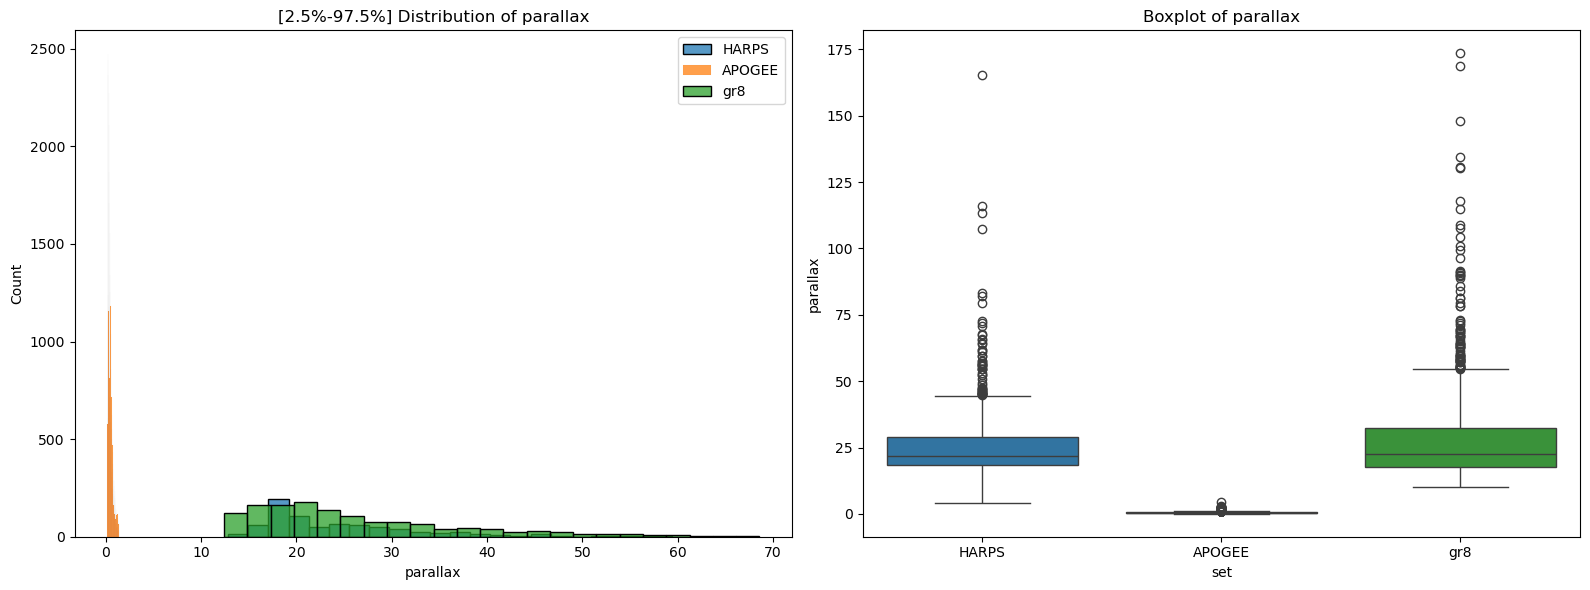

In [99]:
#for feature in cols_for_ml:
#    print(feature)
#    plot_distribution_trio(harps_combined, apogee_renamed, galah_renamed, feature=feature, labels=("HARPS", "APOGEE", "GALAH"))

# Use appropriate renamings if not done already
plot_distribution_trio(harps, apogee, gr8, feature='parallax', labels=("HARPS", "APOGEE", "gr8"))


In [100]:
def plot_element_minus_feh_vs_feh(dfs, element='mg_h', labels=None, colors=None):
    """
    Plots [X/H] - [Fe/H] vs [Fe/H] for 2 or 3 DataFrames, with mean [X/Fe] in [-0.1, 0.1] annotated.

    Parameters:
        dfs: list of 2 or 3 pandas DataFrames
        element: string, element column name (e.g., 'mg_h')
        labels: list of labels (same length as dfs)
        colors: list of colors (same length as dfs)
    """
    if not (2 <= len(dfs) <= 3):
        raise ValueError("Please provide 2 or 3 DataFrames.")

    if labels is None:
        labels = [f'DF{i+1}' for i in range(len(dfs))]
    if len(labels) != len(dfs):
        raise ValueError("Length of 'labels' must match number of DataFrames.")

    if colors is None:
        default_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
        colors = default_colors[:len(dfs)]

    fig, ax = plt.subplots(figsize=(10, 6))
    label_elem = element.split("_")[0].capitalize()
    y_offset = 0.05

    for i, (df, label, color) in enumerate(zip(dfs, labels, colors)):
        try:
            x = pd.to_numeric(df['fe_h'], errors='coerce')
            y = pd.to_numeric(df[element], errors='coerce')
            mask = x.notna() & y.notna()
            x = x[mask]
            y = y[mask]
            delta = y - x

            ax.scatter(x, delta, alpha=0.5, label=label, s=20, color=color)

            sel_mask = (x >= -0.1) & (x <= 0.1)
            if sel_mask.sum() >= 5:
                mean_val = delta[sel_mask].mean()
                ax.annotate(
                    f"{label}: {mean_val:.3f}",
                    xy=(0.05, 0.05 + i * y_offset),
                    xycoords='data',
                    color=color,
                    fontsize=10,
                    ha='left',
                    va='center',
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, lw=1)
                )
        except Exception as e:
            print(f"Skipping {label} due to error: {e}")

    ax.axhline(0, color='gray', linestyle='--', lw=1)
    ax.set_xlabel('[Fe/H]')
    ax.set_ylabel(f'[{label_elem}/Fe]')
    ax.set_title(f'[{label_elem}/Fe] vs [Fe/H]')
    ax.legend()
    ax.grid(True)
    plt.tight_layout()
    plt.show()


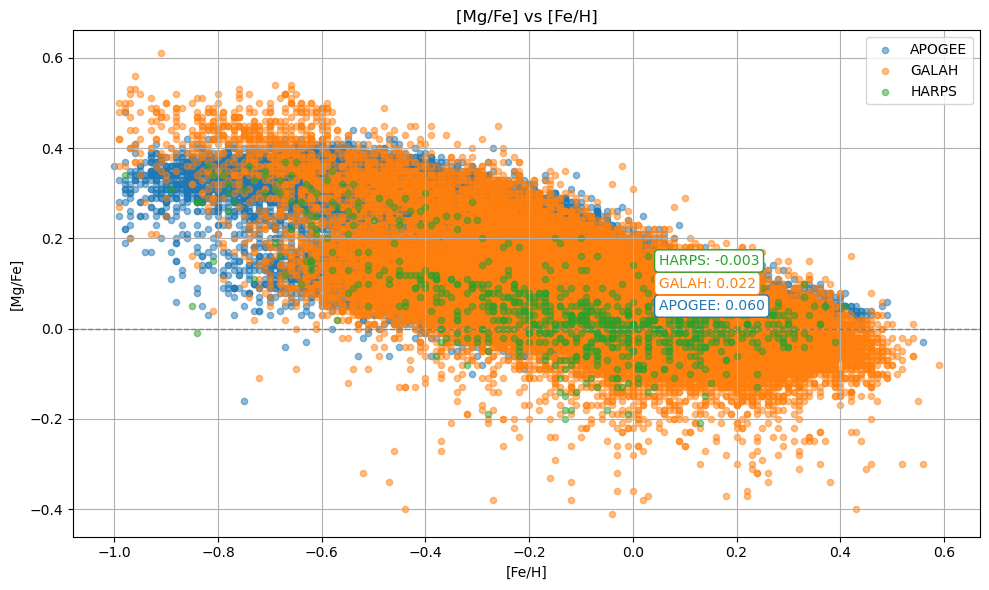

In [101]:
plot_element_minus_feh_vs_feh(
    dfs=[apogee, galah, harps],
    element='mg_h',
    labels=[ 'APOGEE', 'GALAH', 'HARPS']
)
